
# Hotel Booking Cancellation Prediction

## Task 3: Modeling and Evaluation

### Business Objective
Build a baseline machine learning model to predict whether a hotel booking will be cancelled.

### Business Problem
Hotel cancellations can affect room availability, revenue planning, and hotel operations. Predicting cancellations may help hotels improve planning.

### Target Variable
- `is_canceled = 0`: Booking was not cancelled
- `is_canceled = 1`: Booking was cancelled

### Modeling Approach
We will build a Logistic Regression classification model and evaluate its performance using suitable metrics.

### Project Scope
Data loading, feature selection, preprocessing, model training, evaluation, and limitations.


In [2]:

import pandas as pd
import numpy as np

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# Load the prepared hotel booking dataset
df = pd.read_csv("../Data/cleaned_data.csv")

# Display the first 5 rows
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,1
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2


In [4]:

# Check the total number of rows and columns
print("Dataset shape:", df.shape)

# Count all booking records
print("Total bookings:", len(df))

# Check the column names
print("Total columns:", len(df.columns))


Dataset shape: (87396, 33)
Total bookings: 87396
Total columns: 33


In [5]:

# Count bookings in each cancellation category
print(df["is_canceled"].value_counts().sort_index())

# Calculate the percentage of each category
print("\nBooking percentages:")
print(
    (df["is_canceled"].value_counts(normalize=True).sort_index() * 100).round(2)
)


is_canceled
0    63371
1    24025
Name: count, dtype: int64

Booking percentages:
is_canceled
0    72.51
1    27.49
Name: proportion, dtype: float64


In [6]:

# Select the input features for the model
features = [
    "hotel",
    "lead_time",
    "deposit_type",
    "market_segment"
]

X = df[features]

# Select the target we want to predict
y = df["is_canceled"]

print("Input features:", X.columns.tolist())
print("Input data shape:", X.shape)
print("Target shape:", y.shape)


Input features: ['hotel', 'lead_time', 'deposit_type', 'market_segment']
Input data shape: (87396, 4)
Target shape: (87396,)


In [10]:

%pip install scikit-learn


   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 3.0 MB/s eta 0:00:03
   ----- ---------------------------------- 1.0/8.2 MB 4.0 MB/s eta 0:00:02
   ----- ---------------------------------- 1.0/8.2 MB 4.0 MB/s eta 0:00:02
   ------ --------------------------------- 1.3/8.2 MB 1.4 MB/s eta 0:00:05
   ---------- ----------------------------- 2.1/8.2 MB 2.0 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.2 MB 2.0 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.2 MB 2.0 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.2 MB 2.0 MB/s eta 0:00:04
   ----------- ---------------------------- 2.4

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns
numeric_features = ["lead_time"]
categorical_features = [
    "hotel",
    "deposit_type",
    "market_segment"
]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 69916
Testing records: 17480


In [12]:

# Preprocess numerical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each column type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [13]:

# Combine preprocessing and Logistic Regression
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Baseline model created successfully!")


Baseline model created successfully!


In [14]:

# Train the model using training data
model.fit(X_train, y_train)

print("Model training completed successfully!")



Model training completed successfully!


In [15]:

# Predict cancellation for the testing data
y_pred = model.predict(X_test)

# Display the first 10 actual and predicted results
results = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_pred[:10]
})

print(results)


   Actual  Predicted
0       0          1
1       0          0
2       0          0
3       1          0
4       1          0
5       0          0
6       0          0
7       1          1
8       1          0
9       0          0


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

# Show detailed performance for both classes
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.7399
Precision: 0.6249
Recall: 0.1349
F1-score: 0.2218

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.97      0.84     12675
           1       0.62      0.13      0.22      4805

    accuracy                           0.74     17480
   macro avg       0.69      0.55      0.53     17480
weighted avg       0.71      0.74      0.67     17480

Confusion Matrix:
[[12286   389]
 [ 4157   648]]


In [17]:

# Simple baseline: predict that no booking will be cancelled
baseline_predictions = np.zeros(len(y_test), dtype=int)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

model_accuracy = accuracy_score(y_test, y_pred)

print("Simple baseline accuracy:", round(baseline_accuracy * 100, 2), "%")
print("Logistic Regression accuracy:", round(model_accuracy * 100, 2), "%")
print(
    "Accuracy improvement:",
    round((model_accuracy - baseline_accuracy) * 100, 2),
    "percentage points"
)


Simple baseline accuracy: 72.51 %
Logistic Regression accuracy: 73.99 %
Accuracy improvement: 1.48 percentage points


In [18]:

# Create a second model that gives more weight to both classes
balanced_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train the balanced model
balanced_model.fit(X_train, y_train)

# Predict on the same test data
balanced_predictions = balanced_model.predict(X_test)

# Evaluate the balanced model
print(
    "Accuracy:",
    round(accuracy_score(y_test, balanced_predictions), 4)
)
print(
    "Precision:",
    round(precision_score(y_test, balanced_predictions, zero_division=0), 4)
)
print(
    "Recall:",
    round(recall_score(y_test, balanced_predictions, zero_division=0), 4)
)
print(
    "F1-score:",
    round(f1_score(y_test, balanced_predictions, zero_division=0), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, balanced_predictions))


Accuracy: 0.6034
Precision: 0.3886
Recall: 0.7717
F1-score: 0.5169

Confusion Matrix:
[[6840 5835]
 [1097 3708]]


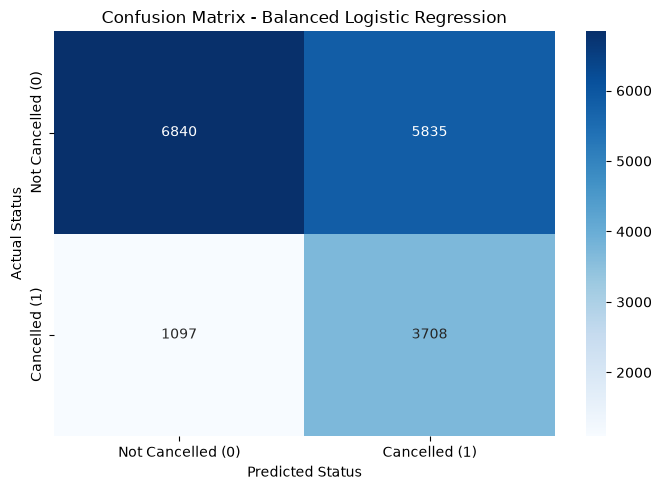

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix for the balanced model
cm = confusion_matrix(y_test, balanced_predictions)

# Create the heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Cancelled (0)", "Cancelled (1)"],
    yticklabels=["Not Cancelled (0)", "Cancelled (1)"]
)

plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.tight_layout()
plt.show()



## Model Limitations

1. **Low precision:** The balanced model achieved 38.86% precision. Many bookings predicted as cancelled were not actually cancelled.

2. **False positives:** The model incorrectly flagged 5,835 bookings as cancellations. This could lead to unnecessary follow-up work for hotel staff.

3. **Missed cancellations:** The model missed 1,097 actual cancellations, even though it detected more cancellations than the original model.

4. **Limited features:** The model uses only hotel type, lead time, deposit type, and market segment. Additional relevant booking information may improve predictions.

5. **Baseline model:** Logistic Regression is a simple starting point. Other algorithms and parameter settings may perform differently.

6. **Historical data:** Patterns in the dataset may not represent future booking behavior.

7. **Further validation required:** The model has not been tested in a real hotel operation. Its predictions should not be used for production decisions without further evaluation.

## Conclusion

Two Logistic Regression models were trained and evaluated using the same training and testing split.

The original model achieved 73.99% accuracy but only 13.49% recall for cancellations. The balanced model achieved 60.34% accuracy, 77.17% recall, and a 51.69% F1-score for cancellations.

The balanced model identified more actual cancellations, but its precision was lower at 38.86%, resulting in many false-positive predictions.

The results demonstrate why model evaluation should consider multiple metrics rather than accuracy alone. Further feature engineering, model comparison, and validation are required before selecting a model for business use.


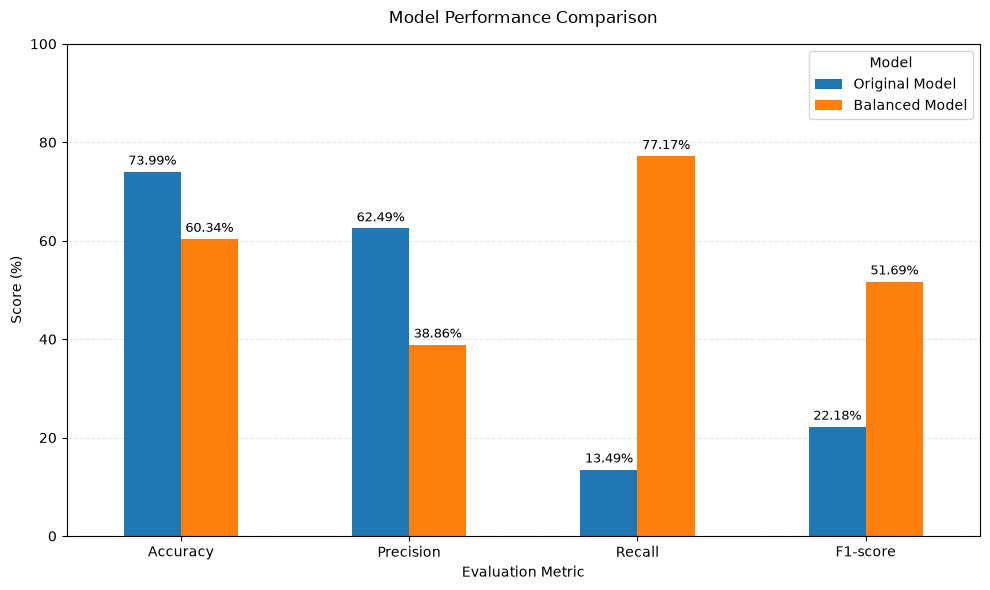

In [22]:

comparison = pd.DataFrame({
    "Original Model": [
        accuracy_score(y_test, y_pred) * 100,
        precision_score(y_test, y_pred, zero_division=0) * 100,
        recall_score(y_test, y_pred, zero_division=0) * 100,
        f1_score(y_test, y_pred, zero_division=0) * 100
    ],
    "Balanced Model": [
        accuracy_score(y_test, balanced_predictions) * 100,
        precision_score(y_test, balanced_predictions, zero_division=0) * 100,
        recall_score(y_test, balanced_predictions, zero_division=0) * 100,
        f1_score(y_test, balanced_predictions, zero_division=0) * 100
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])

ax = comparison.plot(kind="bar", figsize=(10, 6))

ax.set_title("Model Performance Comparison", pad=15)
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.set_xticklabels(comparison.index, rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

